In [ ]:
#Bài làm mẫu 1: Phân loại hoa Iris
#Nhiệm vụ 1: Xây dựng mô hình SVM

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

In [ ]:
#Đọc dữ liệu và quan sát

In [2]:
iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

df_iris = X.copy()
df_iris["species"] = y.map(
    dict(enumerate(iris.target_names))
)

display(df_iris.head())
print("Kích thước dữ liệu:", df_iris.shape)
print("\nSố lượng từng loài:")
print(df_iris["species"].value_counts())
print("\nDữ liệu thiếu:")
print(df_iris.isnull().sum())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Kích thước dữ liệu: (150, 5)

Số lượng từng loài:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Dữ liệu thiếu:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [ ]:
#Trực quan hóa dữ liệu

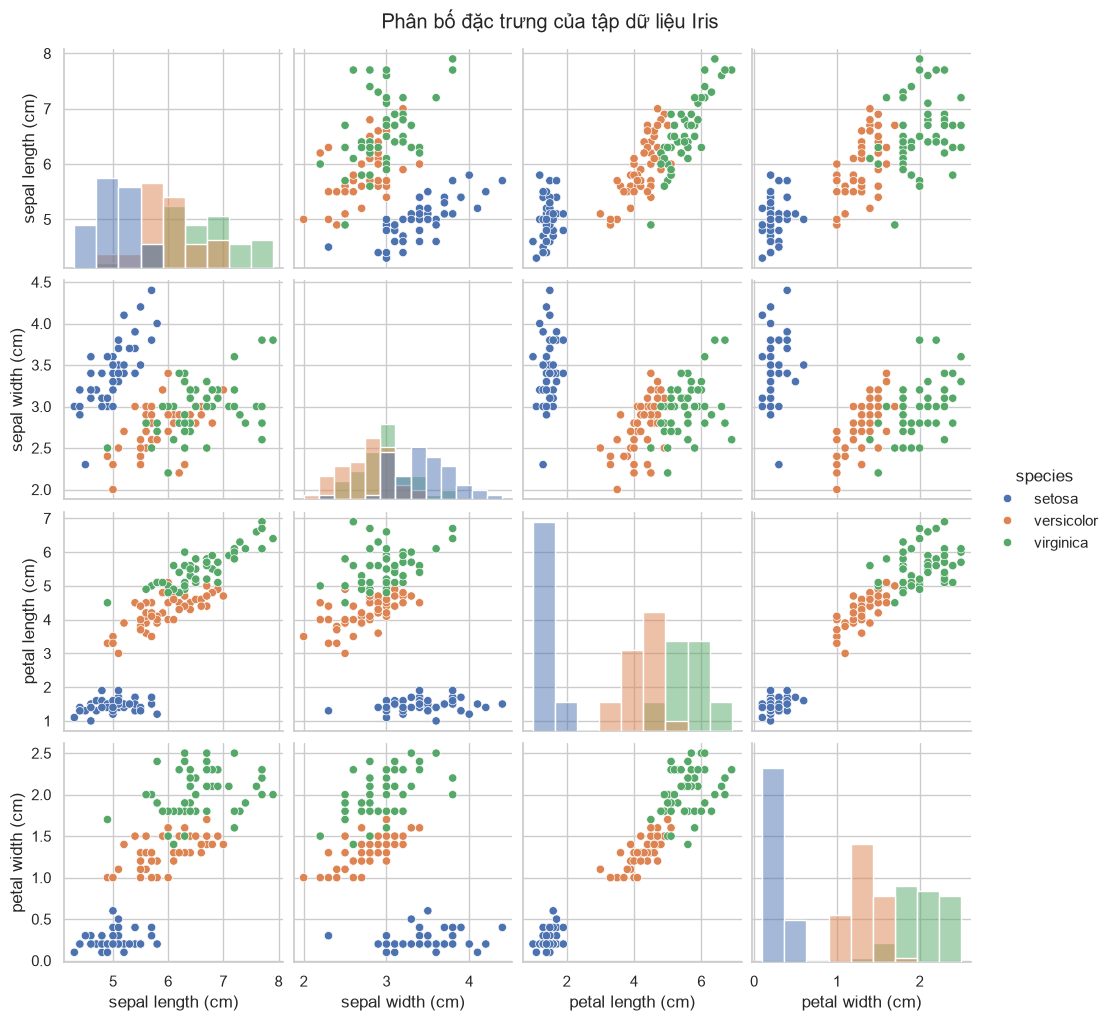

In [3]:
sns.pairplot(
    df_iris,
    hue="species",
    diag_kind="hist"
)
plt.suptitle("Phân bố đặc trưng của tập dữ liệu Iris", y=1.02)
plt.show()

In [ ]:
#Chia dữ liệu và xây dựng SVM

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print("Số mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nBáo cáo phân loại:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    zero_division=0
))

Số mẫu train: 120
Số mẫu test: 30
Accuracy: 0.9667

Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
#Vẽ ma trận nhầm lẫn

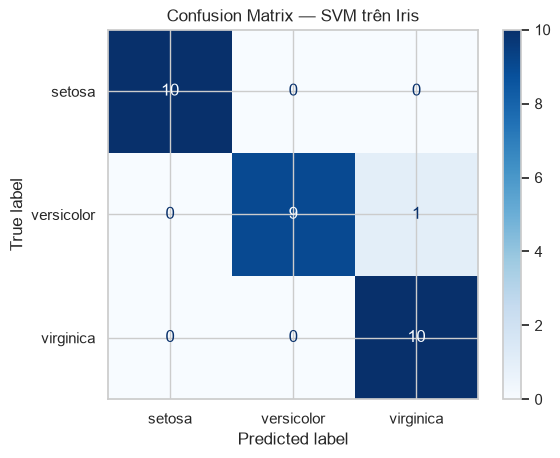

In [5]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — SVM trên Iris")
plt.show()

In [ ]:
#Thử dự đoán một mẫu hoa

In [6]:
sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

predicted_class = svm_model.predict(sample)[0]

print("Loài hoa dự đoán:", iris.target_names[predicted_class])

Loài hoa dự đoán: setosa


In [ ]:
#Vẽ ranh giới phân loại bằng hai đặc trưng

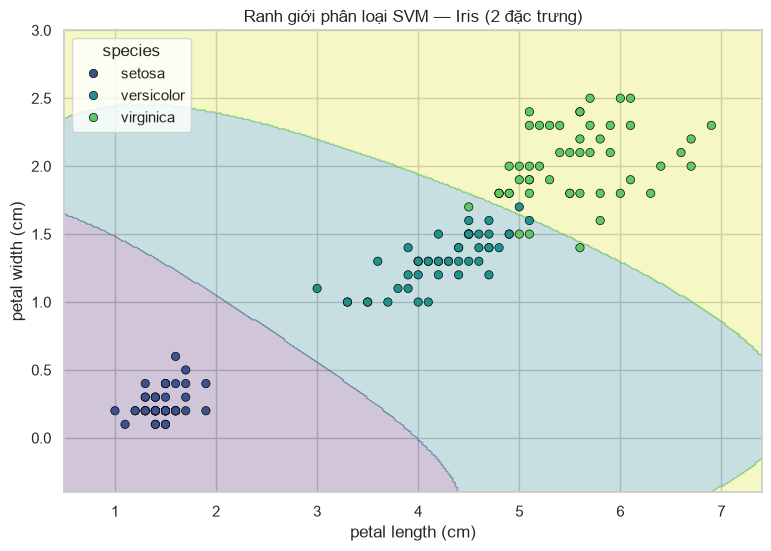

In [7]:
X_2d = X[["petal length (cm)", "petal width (cm)"]]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

svm_2d.fit(X_train_2d, y_train_2d)

x_min, x_max = X_2d.iloc[:, 0].min() - 0.5, X_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_2d.iloc[:, 1].min() - 0.5, X_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "petal length (cm)": xx.ravel(),
    "petal width (cm)": yy.ravel()
})

Z = svm_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
sns.scatterplot(
    data=df_iris,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    palette="viridis",
    edgecolor="black"
)
plt.title("Ranh giới phân loại SVM — Iris (2 đặc trưng)")
plt.show()